# Brain MRI — Image Segmentation Project

Experiment with **image segmentation** with different techniques. 

- **Dataset:** Brain MRI images with COCO annotations, split into `train`, `valid`, and `test`.
- **Labels:** `0 = background`, `1 = annotated region`.

> **Dataset limitation:** the provided COCO polygons are rectangular bounding-box annotations, not precise outlines. The generated binary masks indicate annotated rectangles, so this is closer to detection than precise semantic segmentation.

## 0. Setup

In [10]:
from pathlib import Path
from collections import defaultdict
import json

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

In [11]:
# Reproducible random sampling
SEED = 42

# Relative paths: the dataset is not committed to Git
DATA_DIR = Path("data")
TRAIN_DIR = DATA_DIR / "train"
VALID_DIR = DATA_DIR / "valid"
TEST_DIR = DATA_DIR / "test"

for split_dir in (TRAIN_DIR, VALID_DIR, TEST_DIR):
    annotations_file = split_dir / "_annotations.coco.json"

## 1. Dataset and ground-truth masks

In [ ]:
class MRIDataset:
    def __init__(self, directory):
        self.directory = directory

        # Load COCO metadata and annotations
        with (directory / "_annotations.coco.json").open("r", encoding="utf-8") as f:
            coco = json.load(f)

        self.images = coco["images"]
        self.annotations = defaultdict(list)

        # Group annotations by image ID
        for annotation in coco["annotations"]:
            self.annotations[annotation["image_id"]].append(annotation)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image_info = self.images[index]
        image_path = self.directory / image_info["file_name"] # Load the grayscale image

        with Image.open(image_path) as img:
            image = np.asarray(img.convert("L"))

        mask = self._create_mask(image_info) # Create the corresponding binary mask

        return image, mask

    def _create_mask(self, image_info):
        width, height = image_info["width"], image_info["height"]

        mask_image = Image.new("L", (width, height), 0)
        draw = ImageDraw.Draw(mask_image)

        # Draw all polygons belonging to the image
        for annotation in self.annotations.get(image_info["id"], []):
            for polygon in annotation["segmentation"]:
                points = list(zip(polygon[0::2], polygon[1::2]))

                if len(points) >= 3:
                    draw.polygon(points, fill=1)
                    
        return np.asarray(mask_image, dtype=bool)

In [18]:
# Load datasets
data_tr = MRIDataset(TRAIN_DIR)
data_val = MRIDataset(VALID_DIR)
data_te = MRIDataset(TEST_DIR)

print(f"Training images:   {len(data_tr)}")
print(f"Validation images: {len(data_val)}")
print(f"Testing images:    {len(data_te)}")

Training images:   1502
Validation images: 429
Testing images:    215


### 1.1. Visualize images and corresponding masks

Show 10 random images from the training set alongside it's binary mask image. 

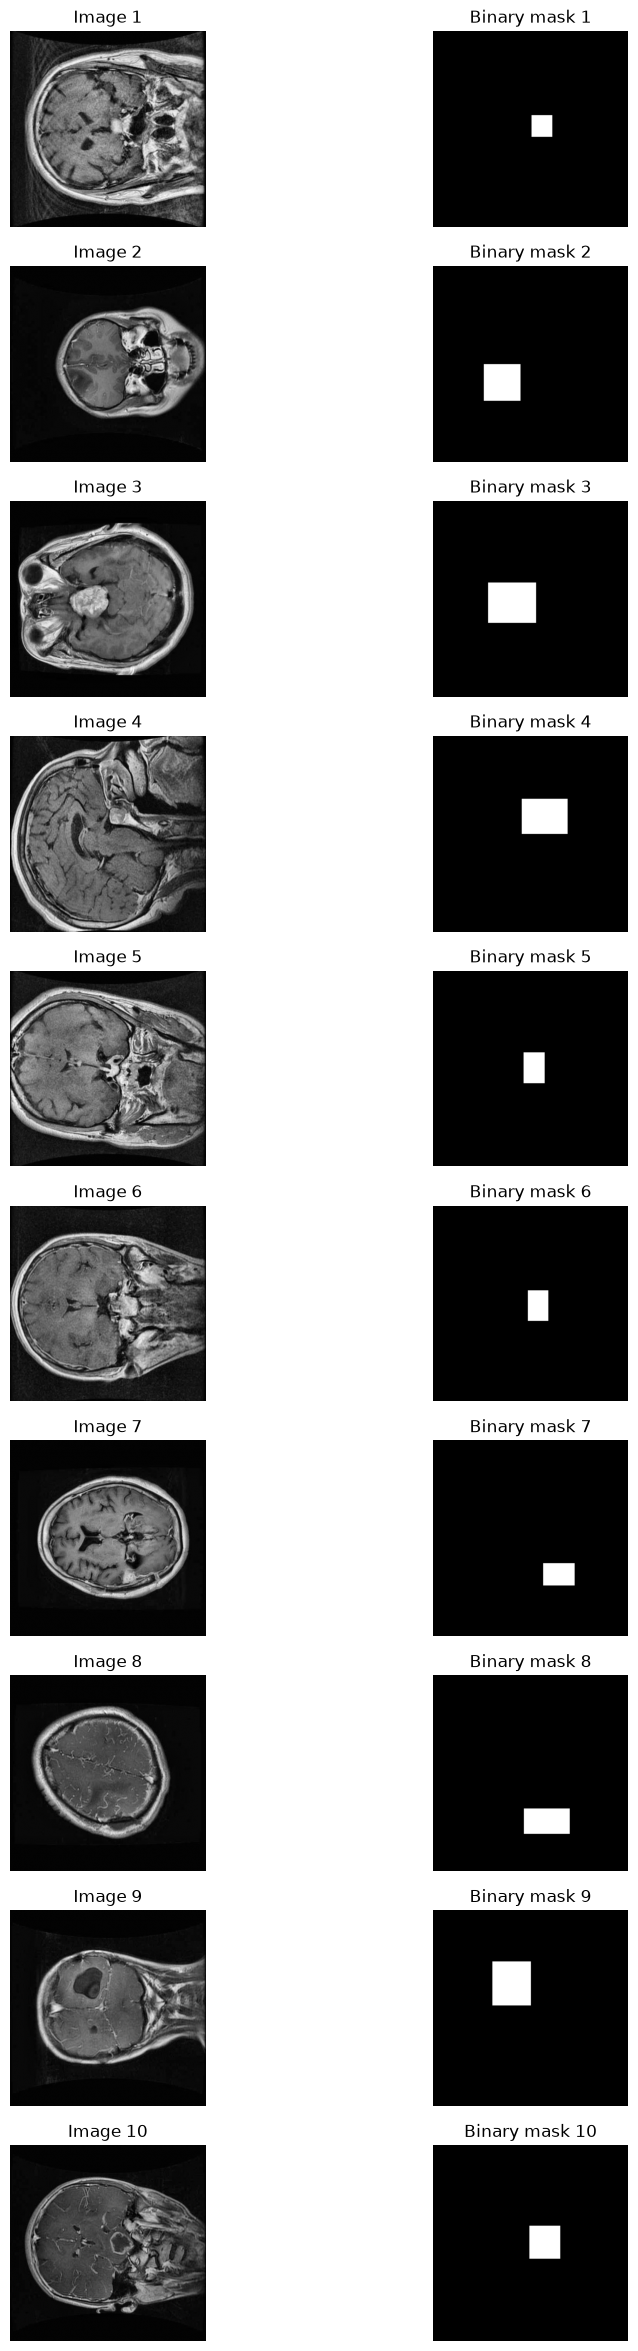

In [29]:
def show_image_mask_pairs(dataset, n_images=10, seed=SEED):
    rng = np.random.default_rng(seed)

    indices = rng.choice(len(dataset), size=min(n_images, len(dataset)), replace=False)

    fig, axes = plt.subplots(
        len(indices), 2, 
        figsize=(len(indices), len(indices) * 3)
    )

    for row, index in enumerate(indices):
        image, mask = dataset[index]

        axes[row, 0].imshow(image, cmap="gray", vmin=0, vmax=255)
        axes[row, 0].set_title(f"Image {row + 1}")

        axes[row, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
        axes[row, 1].set_title(f"Binary mask {row + 1}")

        for ax in axes[row]:
            ax.axis("off")

    plt.show()


show_image_mask_pairs(data_tr)

## 2. Part 1.1 — Segmentation by individual pixel classification

Each sampled pixel is one training example:

- **Feature `X`:** a single grayscale intensity, normalized to `[0, 1]`.
- **Label `y`:** the value of the ground-truth mask at the **same coordinates** (`0` or `1`).

In [37]:
def sample_pixels(dataset, n_pixels, seed=SEED):
    rng = np.random.default_rng(seed)

    features = []
    labels = []

    for image, mask in dataset:
        height, width = image.shape

        rows = rng.integers(0, height, size=n_pixels)
        cols = rng.integers(0, width, size=n_pixels)

        features.append(image[rows, cols].astype(np.float32).reshape(-1, 1) / 255.0)
        labels.append(mask[rows, cols].astype(np.uint8))

    return np.vstack(features), np.concatenate(labels)

In [38]:
N_PIXELS_PER_IMAGE = 100

features_tr, labels_tr = sample_pixels(data_tr, N_PIXELS_PER_IMAGE)
features_val, labels_val = sample_pixels(data_val, N_PIXELS_PER_IMAGE)
features_te, labels_te = sample_pixels(data_te, N_PIXELS_PER_IMAGE)

In [34]:
for name, X, y in (
    ("Training", features_tr, labels_tr),
    ("Validation", features_val, labels_val),
    ("Testing", features_te, labels_te),
):
    print(f"{name:10s} features={X.shape}, labels={y.shape}")

Training   features=(150200, 1), labels=(150200,)
Validation features=(42900, 1), labels=(42900,)
Testing    features=(21500, 1), labels=(21500,)


### 2.1. Baseline: standard Logistic Regression

Train a simple binary classifier using only one pixel's intensity. The standard model does **not** compensate for the large difference between the number of background and annotated pixels.

In [44]:
clf_standard = LogisticRegression(max_iter=1000, random_state=SEED)
clf_standard.fit(features_tr, labels_tr)
print("Standard Logistic Regression trained.")

Standard Logistic Regression trained.


### 2.2. Evaluation: Accuracy, AUC, and confusion matrix

Evaluate on the validation and test samples. Precision and recall are also displayed to clarify what happens to the minority class. An AUC above 0.5 can coexist with zero positive predictions at the default decision threshold of 0.5.

In [45]:
def evaluate_classifier(model, features, labels, title):
    """Print binary-classification metrics and display a confusion matrix."""
    predicted = model.predict(features)
    positive_probabilities = model.predict_proba(features)[:, 1]

    print(f"{title}")
    print(f"  Accuracy:  {accuracy_score(labels, predicted):.4f}")
    print(f"  AUC:       {roc_auc_score(labels, positive_probabilities):.4f}")
    print(f"  Precision: {precision_score(labels, predicted, zero_division=0):.4f}")
    print(f"  Recall:    {recall_score(labels, predicted, zero_division=0):.4f}")

    cm = confusion_matrix(labels, predicted, labels=[0, 1])
    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Background", "Annotated area"],
    )
    display.plot(cmap="Blues")
    plt.title(title)
    plt.show()

Standard — Validation
  Accuracy:  0.9614
  AUC:       0.7120
  Precision: 0.0000
  Recall:    0.0000


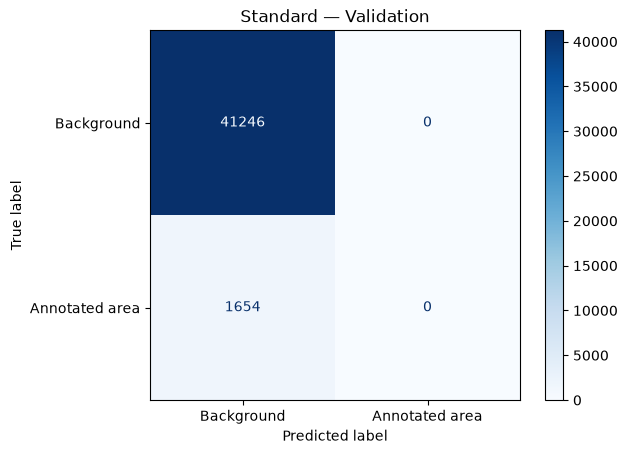

Standard — Test
  Accuracy:  0.9636
  AUC:       0.7182
  Precision: 0.0000
  Recall:    0.0000


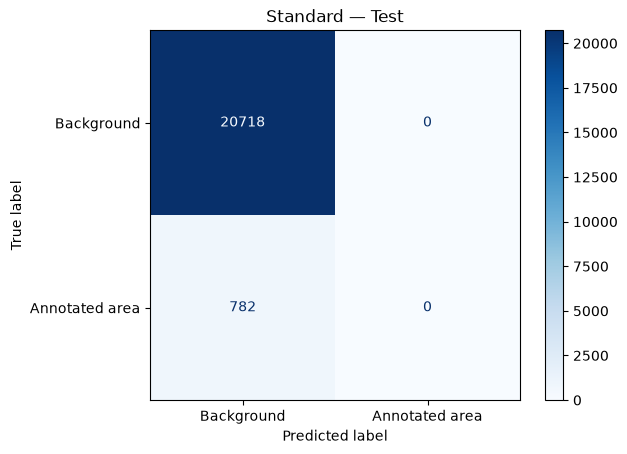

In [46]:
evaluate_classifier(clf_standard, features_val, labels_val, "Standard — Validation")
evaluate_classifier(clf_standard, features_te, labels_te, "Standard — Test")

### 2.3. Comparison: class-weighted Logistic Regression

We keep the **same algorithm and the same data** but add `class_weight="balanced"`. This makes errors on the minority class more costly during training. It may improve positive-class recall, while increasing false positives.

Use validation results for model comparisons; test results are shown here to document the experiments already performed, not to tune the classifier further.

Balanced — Validation
  Accuracy:  0.6357
  AUC:       0.7120
  Precision: 0.0638
  Recall:    0.6185


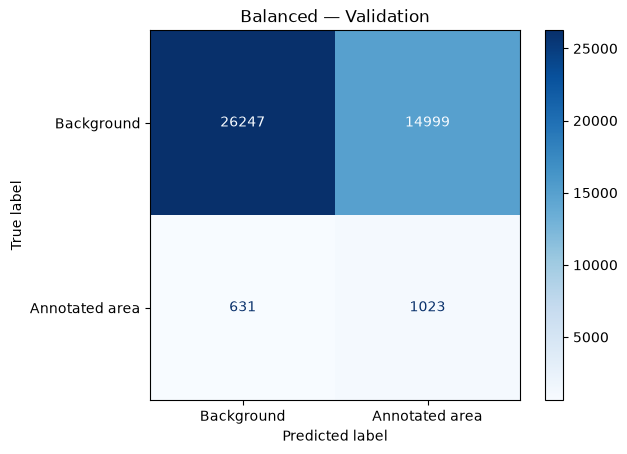

Balanced — Test
  Accuracy:  0.6328
  AUC:       0.7182
  Precision: 0.0633
  Recall:    0.6586


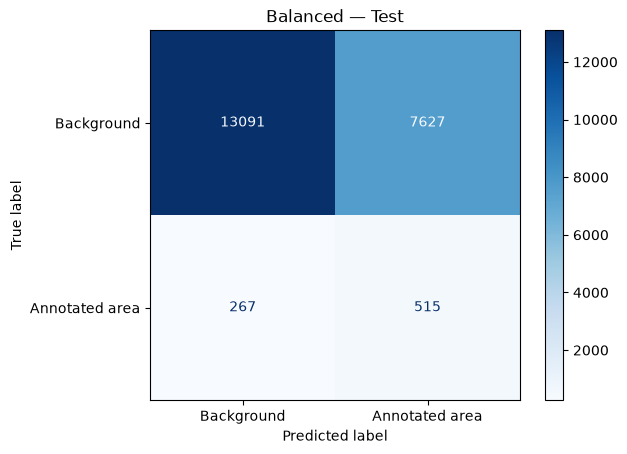

In [47]:
clf_balanced = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)
clf_balanced.fit(features_tr, labels_tr)

evaluate_classifier(clf_balanced, features_val, labels_val, "Balanced — Validation")
evaluate_classifier(clf_balanced, features_te, labels_te, "Balanced — Test")

### 2.4. Apply the classifiers to complete test images

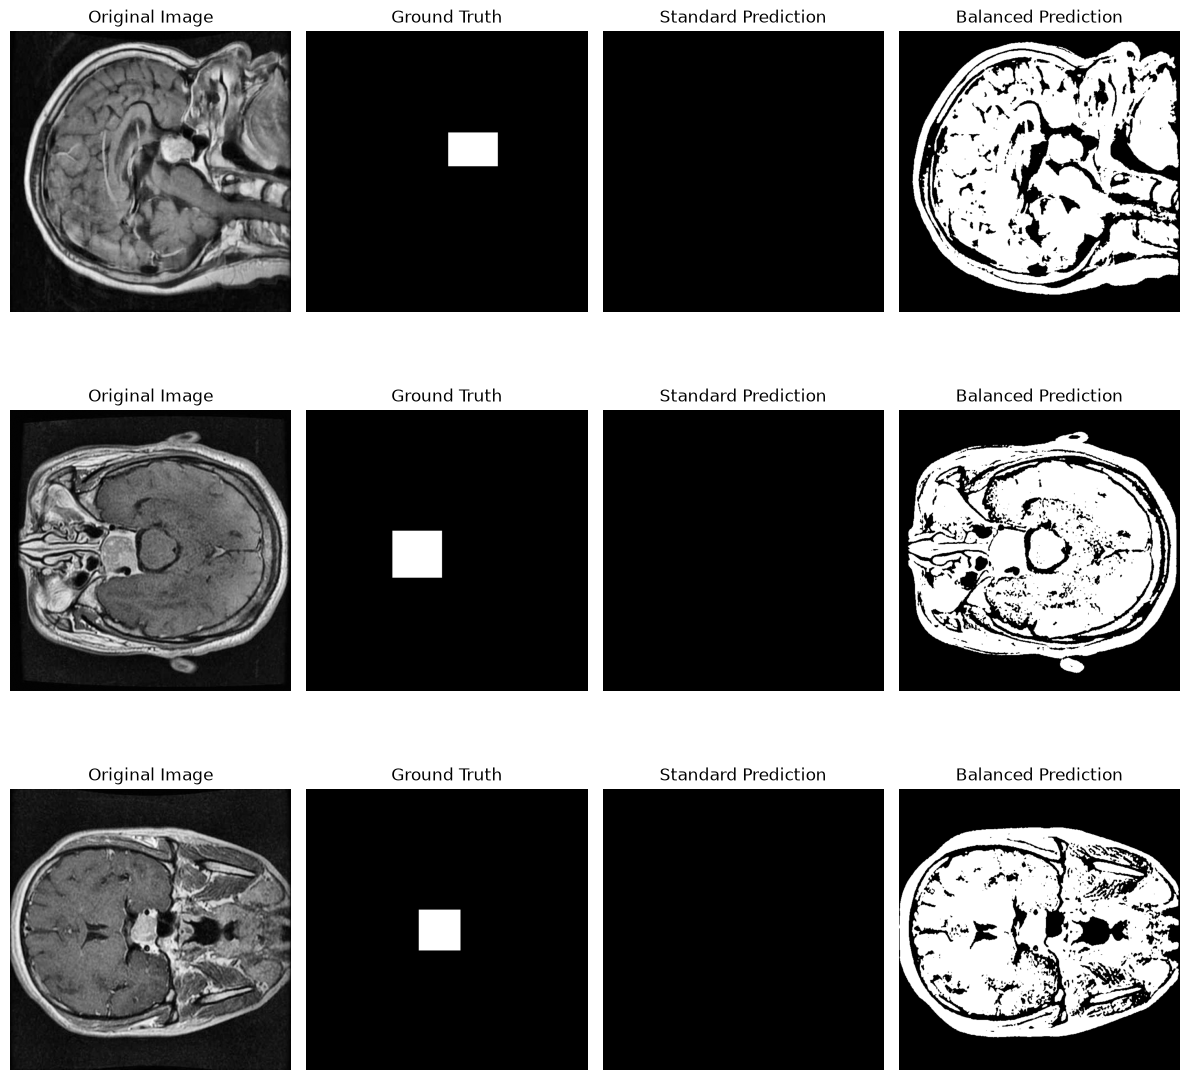

In [ ]:
def predict_binary_mask(model, image):
    height, width = image.shape

    features = image.astype(np.float32).reshape(-1, 1) / 255.0
    predictions = model.predict(features)

    return predictions.reshape(height, width)


N_TEST_IMAGES = 3 # Predictions for 3 images

fig, axes = plt.subplots(
    N_TEST_IMAGES, 4,
    figsize=(12, 4 * N_TEST_IMAGES)
)

for row in range(N_TEST_IMAGES):
    image, mask = data_te[row]

    standard_mask = predict_binary_mask(clf_standard, image)
    balanced_mask = predict_binary_mask(clf_balanced, image)

    axes[row, 0].imshow(image, cmap="gray", vmin=0, vmax=255)
    axes[row, 0].set_title("Original Image")

    axes[row, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title("Ground Truth")

    axes[row, 2].imshow(standard_mask, cmap="gray", vmin=0, vmax=1)
    axes[row, 2].set_title("Standard Prediction")

    axes[row, 3].imshow(balanced_mask, cmap="gray", vmin=0, vmax=1)
    axes[row, 3].set_title("Balanced Prediction")

    for ax in axes[row]:
        ax.axis("off")

fig.tight_layout()
plt.show()

### 2.5. Discussion of the results

The standard Logistic Regression achieves high accuracy because background pixels dominate the samples. In our previous run, it predicted only background, missing all positive pixels.

The balanced model identifies more annotated pixels (higher recall), but also labels large background regions as positive (many false positives and low precision). 

**Neither model provides a reliable tumor outline** because a single grayscale intensity does not contain any spatial context, and the provided ground truth consists of rectangular annotations.

## 3. Part 1.2 — Patch sampling

In [52]:
def pick_random_centers(mask, size=100, ignore=0):
    mask_ignored = mask.copy()
    
    mask_ignored[:ignore,:]=False
    mask_ignored[-ignore:,:]=False
    mask_ignored[:,:ignore]=False
    mask_ignored[:,-ignore:]=False
    
    rs, cs = np.where(mask_ignored)
    ix = np.random.randint(len(rs), size=size)
    return rs[ix], cs[ix]

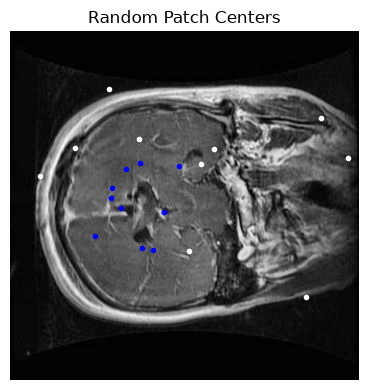

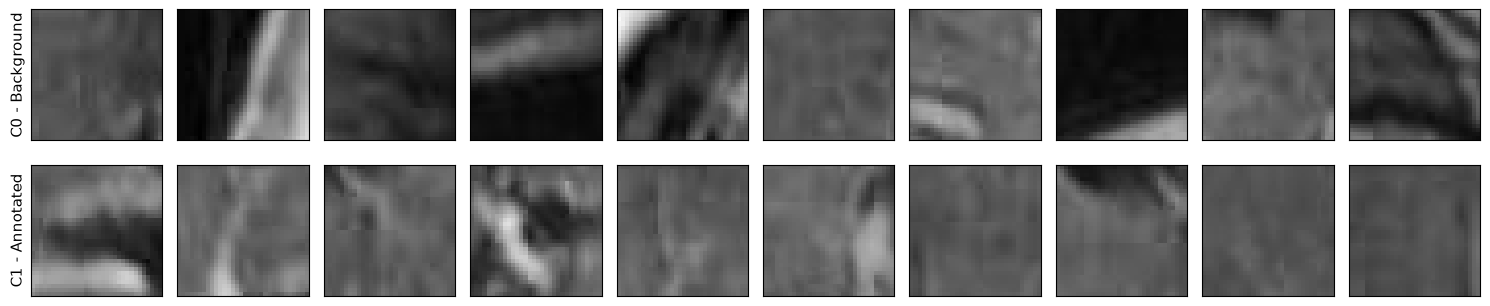

In [68]:
PATCH_SIZE = 32
N_PATCHES_PER_CLASS = 10
half = PATCH_SIZE // 2

# Reproducible sampling
np.random.seed(SEED)

# Load the first training image and its mask
image, mask = data_tr[0]

# Class 0: background
rows_0, cols_0 = pick_random_centers(
    ~mask,
    size=N_PATCHES_PER_CLASS,
    ignore=half
)

# Class 1: annotated area
rows_1, cols_1 = pick_random_centers(
    mask,
    size=N_PATCHES_PER_CLASS,
    ignore=half
)

# Extract patches
patches_0 = [
    image[r-half:r+half, c-half:c+half]
    for r, c in zip(rows_0, cols_0)
]

patches_1 = [
    image[r-half:r+half, c-half:c+half]
    for r, c in zip(rows_1, cols_1)
]

# Visualize the original image with selected patch centers
fig, ax = plt.subplots(figsize=(4, 4))

ax.imshow(image, cmap="gray", vmin=0, vmax=255)

ax.plot(cols_0, rows_0, "w.", label="C0 - Background")
ax.plot(cols_1, rows_1, "b.", label="C1 - Annotated")

ax.set_title("Random Patch Centers")
ax.axis("off")

plt.tight_layout()
plt.show()

# Visualize patches
fig, axes = plt.subplots(
    2, N_PATCHES_PER_CLASS,
    figsize=(15, 3.5)
)

for i in range(N_PATCHES_PER_CLASS):
    axes[0, i].imshow(patches_0[i], cmap="gray", vmin=0, vmax=255)
    axes[1, i].imshow(patches_1[i], cmap="gray", vmin=0, vmax=255)

for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

axes[0, 0].set_ylabel("C0 - Background", fontsize=11)
axes[1, 0].set_ylabel("C1 - Annotated", fontsize=11)

plt.tight_layout()
plt.show()

In [70]:
PATCH_SIZE = 32
N_PATCHES_PER_CLASS = 10
half = PATCH_SIZE // 2

np.random.seed(SEED)

patches_0 = []
patches_1 = []

for image, mask in data_tr:

    # Class 0: background
    rows_0, cols_0 = pick_random_centers(
        ~mask,
        size=N_PATCHES_PER_CLASS,
        ignore=half
    )

    for r, c in zip(rows_0, cols_0):
        patch = image[r-half:r+half, c-half:c+half]
        patches_0.append(patch)

    # Class 1: annotated area
    if np.any(mask[half:-half, half:-half]): # Some images may not have positive annotations
        rows_1, cols_1 = pick_random_centers(
            mask,
            size=N_PATCHES_PER_CLASS,
            ignore=half
        )

        for r, c in zip(rows_1, cols_1):
            patch = image[r-half:r+half, c-half:c+half]
            patches_1.append(patch)

patches_0 = np.array(patches_0)
patches_1 = np.array(patches_1)

print("C0 patches:", patches_0.shape)
print("C1 patches:", patches_1.shape)

C0 patches: (15020, 32, 32)
C1 patches: (15010, 32, 32)


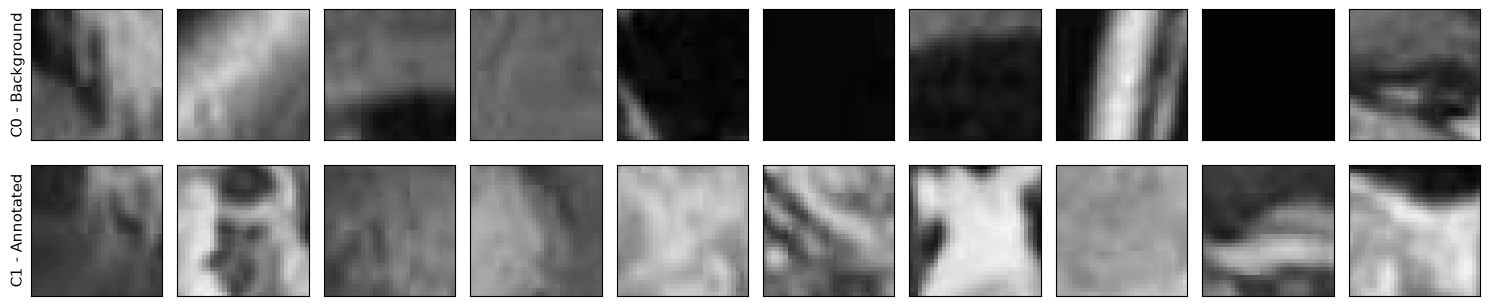

In [71]:
N_PREVIEW_PATCHES = 10

# Select random patches from the complete collections
indices_0 = np.random.choice(
    len(patches_0),
    size=N_PREVIEW_PATCHES,
    replace=False
)

indices_1 = np.random.choice(
    len(patches_1),
    size=N_PREVIEW_PATCHES,
    replace=False
)

# Create the visualization
fig, axes = plt.subplots(
    2, N_PREVIEW_PATCHES,
    figsize=(15, 3.5)
)

for i in range(N_PREVIEW_PATCHES):

    axes[0, i].imshow(
        patches_0[indices_0[i]],
        cmap="gray", vmin=0, vmax=255
    )

    axes[1, i].imshow(
        patches_1[indices_1[i]],
        cmap="gray", vmin=0, vmax=255
    )

for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

axes[0, 0].set_ylabel("C0 - Background", fontsize=11)
axes[1, 0].set_ylabel("C1 - Annotated", fontsize=11)

plt.tight_layout()
plt.show()